# 2. The strength model — did the results actually shift?

Jordan's raw results say one thing and its opponents say another. A team that
beats Cambodia 7–0 and loses 1–3 to Argentina has had two completely different
afternoons, and no table of goal differences can tell them apart.

This notebook builds the instrument that can, and then uses it to answer the
question everything else depends on: **was there a shift, and when?**

1. **The model** — every step, from raw scorelines to a strength number with an interval
2. **The divergence** — why raw results and the model disagree about 2026
3. **The placebo** — is the rise Jordan's, or did the whole region improve?
4. **Calibration** — does the model predict Jordan's own matches?
5. **Where the cut comes from** — locating the shift in time, and what the squad was doing there

Method: a time-weighted Poisson attack/defence model, **Dixon & Coles (1997)**
after **Maher (1982)**, with the hierarchical version of **Baio & Blangiardo
(2010)** standing in as a ridge penalty. Intervals throughout come from a paired
bootstrap; where matches are resampled within a team's own history the blocks are
six-month windows, after **Künsch (1989)**.

```
cd JordanData
python trajectory.py     # the trace
python uncertainty.py    # bootstrap intervals (~30 min)
```

In [1]:
import sys, json
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "JordanData"))
import viz
viz.use_style()

OUT = ROOT / "outputs"
SQUAD = OUT / "squad"
START, CUT = pd.Timestamp("2015-01-01"), pd.Timestamp(viz.SPLIT)
rng = np.random.default_rng(41)

from data import load_results, index_teams, team_view
from baseline import PoissonStrength
from trajectory import build_arrays

df = load_results()
teams, idx = index_teams(df)
ti = idx["Jordan"]
strength = pd.read_csv(OUT / "jordan_strength_ci.csv", parse_dates=["date"])
trace = pd.read_csv(OUT / "jordan_strength_trace.csv", parse_dates=["date"])

## 1. The model

### 1.1 What it assumes

Every team carries two numbers: an **attack** rating and a **defence** rating.
Goals are Poisson, and the rate each side scores at is set by the gap between one
team's attack and the other's defence:

$$\mu_{\text{home}} = \exp(\text{atk}_h - \text{def}_a + \gamma)
\qquad
\mu_{\text{away}} = \exp(\text{atk}_a - \text{def}_h)$$

$\gamma$ is a single global home-advantage term, added only when the match is
not on neutral ground — one number shared by every team, not one per team. Jordan
plays 161 of its 488 matches on neutral ground, so this matters here.

The Dixon–Coles low-score correlation correction is **not** included: the two
scorelines are treated as conditionally independent given the rates.

### 1.2 Recent matches count more

Each match is weighted by its age at the reference date, halving every 730 days:

$$w = 0.5^{\,\text{days before}\,/\,730}$$

This is the most consequential setting in the model — it decides how much history
is allowed to speak.

**Plotted:** the weight a single match carries as a function of how long before
the reference date it was played. Marked points give the weight at two, four and
six years.

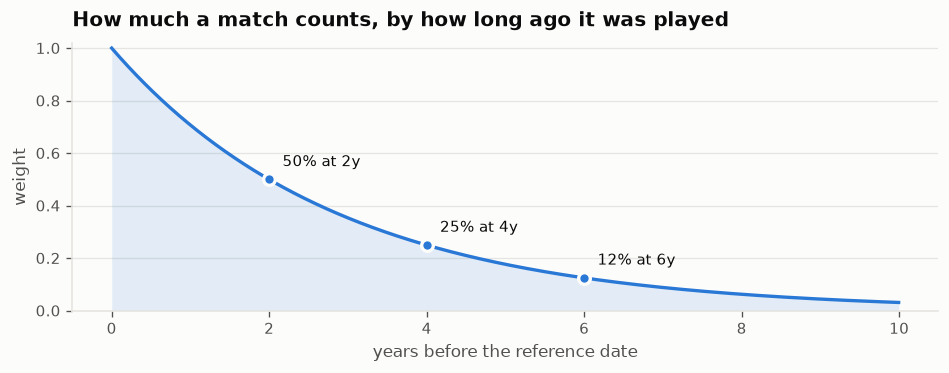

In [2]:
days = np.arange(0, 3651)
w = 0.5 ** (days / 730.0)

fig, ax = plt.subplots(figsize=(7.8, 3.0))
ax.plot(days / 365.25, w, color=viz.BLUE)
ax.fill_between(days / 365.25, 0, w, color=viz.BLUE, alpha=0.12, linewidth=0)
ax.set_title("How much a match counts, by how long ago it was played")
ax.set_xlabel("years before the reference date")
ax.set_ylabel("weight")
ax.set_ylim(0, 1.02)
for yrs in (2, 4, 6):
    val = 0.5 ** (yrs * 365.25 / 730.0)
    ax.plot([yrs], [val], "o", color=viz.BLUE, markersize=7,
            markeredgecolor=viz.SURFACE, markeredgewidth=2, zorder=3)
    ax.annotate(f"{val:.0%} at {yrs}y", xy=(yrs, val), xytext=(8, 8),
                textcoords="offset points", fontsize=9, color=viz.INK)
viz.despine(ax)
plt.show()

So a ten-year lookback window is misleading about how much data really speaks: a
match from nine years ago carries under 2% of the weight of one played today.

**Plotted:** at four reference dates, the raw number of matches in the fitting
window against the **effective** number once the decay weights are applied —
for the whole dataset on the left, and for Jordan alone on the right. The right
panel is the honest sample size behind Jordan's rating.

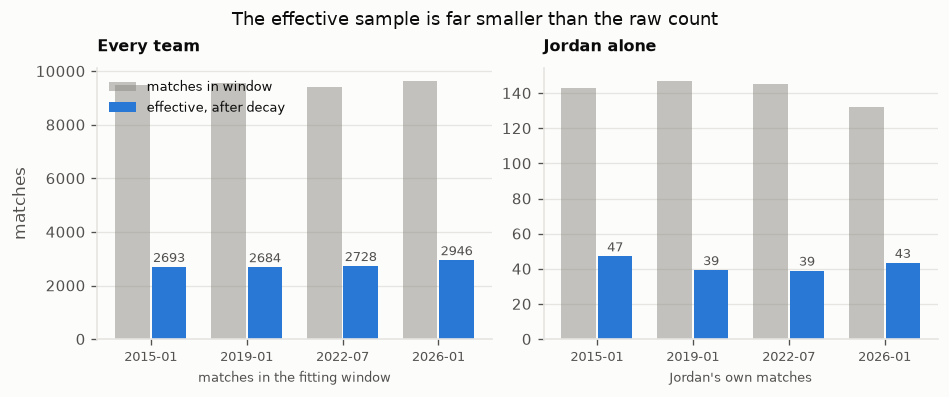

In [3]:
rows = []
for ref in pd.to_datetime(["2015-01-01", "2019-01-01", "2022-07-01", "2026-01-01"]):
    h, a, gh, ga, flag, dd, n, win = build_arrays(df, idx, ref)
    wts = 0.5 ** (dd / 730.0)
    jor = ((win.home_team == "Jordan") | (win.away_team == "Jordan")).to_numpy()
    rows.append({"ref": str(ref.date())[:7], "raw": n, "eff": wts.sum(),
                 "j_raw": int(jor.sum()), "j_eff": wts[jor].sum()})
eff = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.2))
x = np.arange(len(eff))
for ax, (rawc, effc), title, note in (
        (axes[0], ("raw", "eff"), "Every team", "matches in the fitting window"),
        (axes[1], ("j_raw", "j_eff"), "Jordan alone", "Jordan's own matches")):
    ax.bar(x - 0.19, eff[rawc], width=0.36, color=viz.INK_MUTED, alpha=0.5,
           label="matches in window")
    ax.bar(x + 0.19, eff[effc], width=0.36, color=viz.BLUE,
           label="effective, after decay")
    for xi_, v in zip(x + 0.19, eff[effc]):
        ax.annotate(f"{v:.0f}", (xi_, v), xytext=(0, 3), ha="center",
                    textcoords="offset points", fontsize=8, color=viz.INK_2)
    ax.set_xticks(x)
    ax.set_xticklabels(eff.ref, fontsize=8)
    ax.set_title(title, fontsize=9.5)
    ax.set_xlabel(note, fontsize=8)
    viz.despine(ax)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("matches")
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("The effective sample is far smaller than the raw count",
             fontsize=10.5)
plt.show()

🚨 **About 40 effective matches sit behind Jordan's rating, not ~145** — and the
number barely moves across eleven years, because the decay throws away history as
fast as Jordan accumulates it. That is why every interval in this project is
wide, and why *no claim without an interval* is a rule here rather than a
preference.

### 1.3 The penalty, and what it buys

The likelihood alone cannot identify the model: add a constant to every attack
and subtract it from every defence and all predictions are unchanged. An L2
penalty pins them down:

$$\text{objective} = \ell(\theta) - \lambda\Big(\textstyle\sum_i \text{atk}_i^2 + \sum_i \text{def}_i^2\Big), \qquad \lambda = 0.05$$

It does a second job at the same time. A team with three matches on record is
pulled toward the global mean rather than handed an extreme rating on almost no
evidence — partial pooling in all but name (**Hoerl & Kennard 1970**; **Efron &
Morris 1975**), the frequentist stand-in for the hierarchical prior a Bayesian
version would use. $\gamma$ is left unpenalised.

### 1.4 Fitting, and no peeking

675 parameters at once — 337 attacks, 337 defences, one home advantage — by
L-BFGS-B with an analytic gradient, so no numerical differentiation. About 0.1s
per fit.

The trace refits from scratch every six months, each fit seeing **only matches
strictly before its reference date**. The curve is one you could have drawn on
the day, not a retrospective smoothing.

Below is one fit, printed rather than plotted: the arithmetic from parameters to
a strength number, so it can be checked by hand.

In [4]:
ref = pd.Timestamp("2026-01-01")
h, a, gh, ga, flag, dd, n, win = build_arrays(df, idx, ref)
m = PoissonStrength(len(teams)).fit(h, a, gh, ga, flag, dd)

print(f"fit at {ref.date()} on {n:,} matches, nothing after that date")
print(f"converged: {m.converged}")
print(f"  attack   {m.atk[ti]:+.3f}  -> scores   exp({m.atk[ti]:+.3f}) = "
      f"{np.exp(m.atk[ti]):.2f} vs an average defence")
print(f"  defence  {m.dfn[ti]:+.3f}  -> concedes exp({-m.dfn[ti]:+.3f}) = "
      f"{np.exp(-m.dfn[ti]):.2f} vs an average attack")
print(f"  gamma    {m.adv:+.3f}  -> x{np.exp(m.adv):.2f} to the home rate")
print(f"  strength = {np.exp(m.atk[ti]):.2f} - {np.exp(-m.dfn[ti]):.2f} "
      f"= {m.strength(ti):+.3f}")

fit at 2026-01-01 on 9,640 matches, nothing after that date
converged: True
  attack   +0.706  -> scores   exp(+0.706) = 2.03 vs an average defence
  defence  +0.410  -> concedes exp(-0.410) = 0.66 vs an average attack
  gamma    +0.241  -> x1.27 to the home rate
  strength = 2.03 - 0.66 = +1.363


### 1.5 What "strength" means

$$\text{strength}_i = e^{\text{atk}_i} - e^{-\text{def}_i}$$

Set the opponent to an average team — attack and defence both 0 — on neutral
ground. The team then scores $e^{\text{atk}_i}$ and concedes
$e^{-\text{def}_i}$, and the difference is the **expected goal difference
against an average international team on neutral ground**. Jordan at 1.36 means
"would beat a generic average side by about 1.4 goals".

### 1.6 A worked prediction

The model never sees a fixture list — it produces rates for any pairing. Here is
what it expected of Jordan's 2026 matches, fit on data up to the start of 2026,
against what actually happened.

**Plotted:** Jordan's 2026 fixtures, hardest at the bottom. The grey marker is
the goal difference the model expected before kickoff, the orange is what
happened. Almost everything sits left of zero because the opponents were
Argentina, Colombia, Switzerland, Austria, Algeria, Nigeria and Costa Rica.

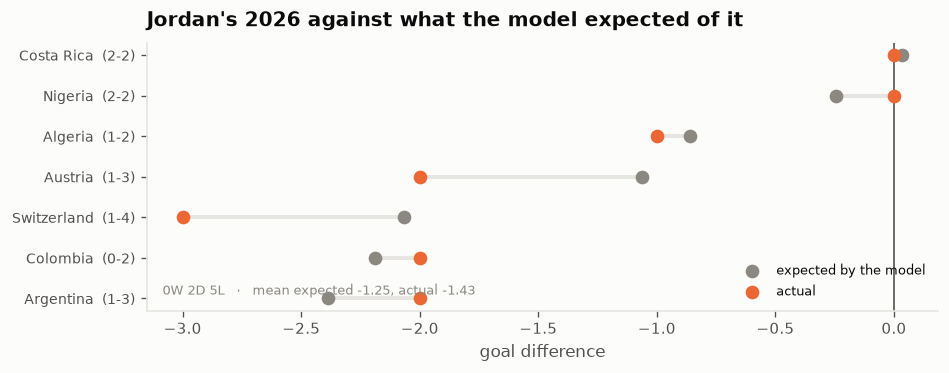

In [5]:
played = team_view(df, "Jordan")
played = played[played.date >= "2026-01-01"]
rows = []
for _, r in played.iterrows():
    oi = idx[r.opponent]
    if r.venue == "away":      # opponent is home, so they get gamma
        mo, mj = m.rates(np.array([oi]), np.array([ti]), np.array([1.0]))
    else:
        flag_ = np.array([1.0 if r.venue == "home" else 0.0])
        mj, mo = m.rates(np.array([ti]), np.array([oi]), flag_)
    rows.append({"opponent": r.opponent, "date": r.date,
                 "expected": float(mj[0] - mo[0]), "actual": int(r.gd),
                 "score": f"{int(r.gf)}-{int(r.ga)}"})
p26 = pd.DataFrame(rows).sort_values("expected")

fig, ax = plt.subplots(figsize=(7.8, 3.0))
y = np.arange(len(p26))
ax.hlines(y, p26.expected, p26.actual, color=viz.GRID, lw=2.4, zorder=1)
ax.scatter(p26.expected, y, color=viz.INK_MUTED, s=52, zorder=3,
           label="expected by the model")
ax.scatter(p26.actual, y, color=viz.ORANGE, s=52, zorder=3, label="actual")
ax.axvline(0, color=viz.INK_2, lw=1.0)
ax.set_yticks(y)
ax.set_yticklabels([f"{r.opponent}  ({r.score})" for r in p26.itertuples()],
                   fontsize=8.5)
ax.set_xlabel("goal difference")
REC = p26.assign(r=np.sign(p26.actual)).r.value_counts()
ax.set_title("Jordan's 2026 against what the model expected of it")
ax.annotate(f"{int(REC.get(1, 0))}W {int(REC.get(0, 0))}D {int(REC.get(-1, 0))}L"
            f"   ·   mean expected {p26.expected.mean():+.2f}, "
            f"actual {p26.actual.mean():+.2f}",
            xy=(0.02, 0.06), xycoords="axes fraction", fontsize=8,
            color=viz.INK_MUTED)
ax.legend(fontsize=8, loc="lower right")
viz.despine(ax)
ax.grid(axis="y", visible=False)
plt.show()

Not a single win, and **the model expected most of it**. Losing 1–3 to Argentina
against an expectation of −2.4 is a slightly *better* than par afternoon and is
scored as one; the 2–2 with Nigeria is a real over-performance. That is opponent
adjustment doing its job, and it sets up section 2.

### 1.7 Where the uncertainty comes from

A point estimate on ~20 effective matches is not a finding. Intervals come from
500 bootstrap draws (**Efron 1979**). Each draw resamples the **full 49k-match
dataset with replacement once**, then re-runs the entire trace on that resample.

Resampling once per draw rather than once per reference date is what makes the
draws **paired across dates**: draw *b* yields a whole trajectory, so a
difference between two dates can be read off draw by draw and gets an interval of
its own. Resampling independently per date would destroy that and leave every
difference uninterpretable.

Nonparametric on purpose. Simulating goals from the fitted Poisson would hold the
fixture list fixed and propagate only scoring noise; resampling matches also
propagates *which matches happened*, which for a team playing 15 a year is the
larger source of uncertainty.

**Plotted:** Jordan's opponent-adjusted strength, refit every six months, with
the 95% bootstrap band. The y-axis is expected goal difference against an average
international team on neutral ground. The dashed line marks mid-2022.

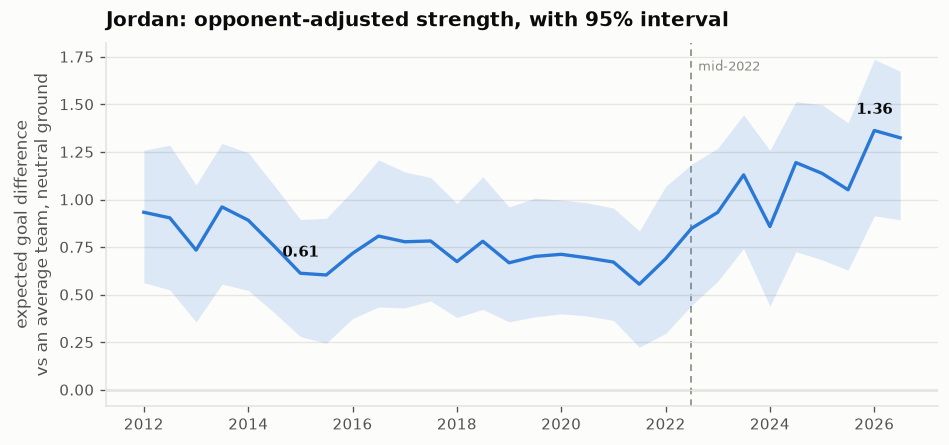

In [6]:
fig, ax = plt.subplots(figsize=(7.8, 3.6))
ax.fill_between(strength.date, strength.strength_lo, strength.strength_hi,
                color=viz.BLUE, alpha=0.15, linewidth=0)
ax.plot(strength.date, strength.strength, color=viz.BLUE)
viz.mark_split(ax)
ax.axhline(0, color=viz.INK_MUTED, linewidth=0.8, zorder=0)
ax.set_title("Jordan: opponent-adjusted strength, with 95% interval")
ax.set_ylabel("expected goal difference" + chr(10) + "vs an average team, neutral ground")
for when in ("2015-01-01", "2026-01-01"):
    r = strength.loc[strength.date == when].iloc[0]
    ax.annotate(f"{r.strength:.2f}", xy=(r.date, r.strength), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=9,
                color=viz.INK, fontweight="bold")
viz.despine(ax)
plt.show()

**The rise is real: +0.717, 95% CI [+0.203, +1.220]** from 2015 to 2026.

🚨 The interval also settles what *cannot* be said. 2026 is the highest point
estimate but is not separable from its neighbours — 2026 against 2023 is +0.411,
CI [−0.031, +0.867]. **"At the top of the range" is supportable; "the peak" is
not.**

### 1.8 Attack and defence separately

Both are log-scale parameters on the same footing, so they share an axis. Higher
defence is *better* — it enters the opponent's rate negatively.

**Plotted:** the two parameters behind the strength number, on the same log
scale, each refit every six months. Attack climbing while defence stays flat is
the shape that the decomposition below puts an interval on.

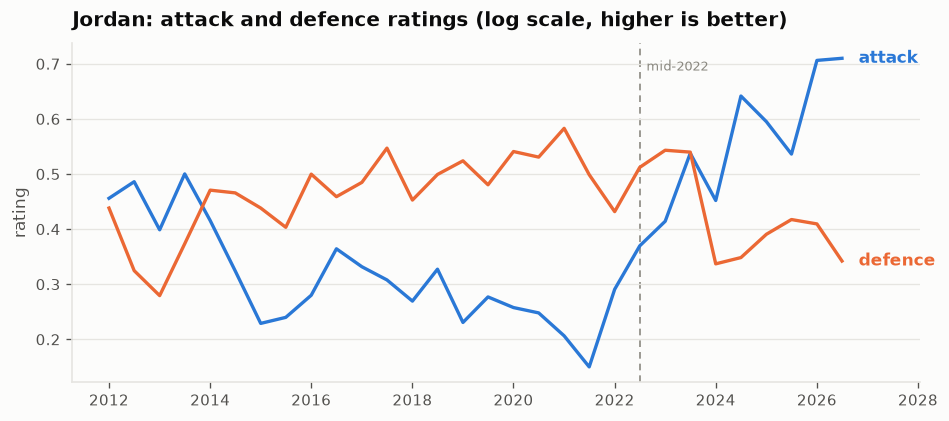

In [7]:
fig, ax = plt.subplots(figsize=(7.8, 3.4))
ax.plot(trace.date, trace.attack, color=viz.BLUE)
ax.plot(trace.date, trace.defence, color=viz.ORANGE)
viz.mark_split(ax)
ax.set_title("Jordan: attack and defence ratings (log scale, higher is better)")
ax.set_ylabel("rating")
ax.set_xlim(right=trace.date.max() + pd.Timedelta(days=560))
last = trace.iloc[-1]
for col, colour in (("attack", viz.BLUE), ("defence", viz.ORANGE)):
    ax.annotate(col, xy=(last.date, last[col]), xytext=(10, 0),
                textcoords="offset points", va="center", fontsize=10,
                color=colour, fontweight="bold")
viz.despine(ax)
plt.show()

Attack climbs from 0.23 to 0.71; defence sits roughly flat. Decomposing the rise
exactly —

$$\Delta\text{strength} = \underbrace{(e^{\text{atk}_1} - e^{\text{atk}_0})}_{\text{attacking}} + \underbrace{(e^{-\text{def}_0} - e^{-\text{def}_1})}_{\text{defensive}}$$

— and putting bootstrap intervals on each part:

| component | 2015→2026 | 95% CI | |
|---|---|---|---|
| attacking contribution | +0.744 | [+0.238, +1.212] | excludes 0 |
| defensive contribution | −0.027 | [−0.255, +0.196] | includes 0 |
| **attack minus defence** | **+0.771** | **[+0.229, +1.282]** | **excludes 0** |

🚨 **The third row is the test that matters** — it compares two uncertain
quantities rather than eyeballing two point estimates. An earlier version of this
claim did exactly the latter and was banned for it. It now holds.

### 1.9 One number that is not about Jordan

$\gamma$ is re-estimated at every refit, and it has been falling steadily across
the whole dataset.

**Plotted:** the single global home-advantage term, refit every six months on the
whole 49k-match record. It is not a Jordan quantity — but a home win in 2026 is
weaker evidence than a home win in 2012, which every expectation in this project
inherits.

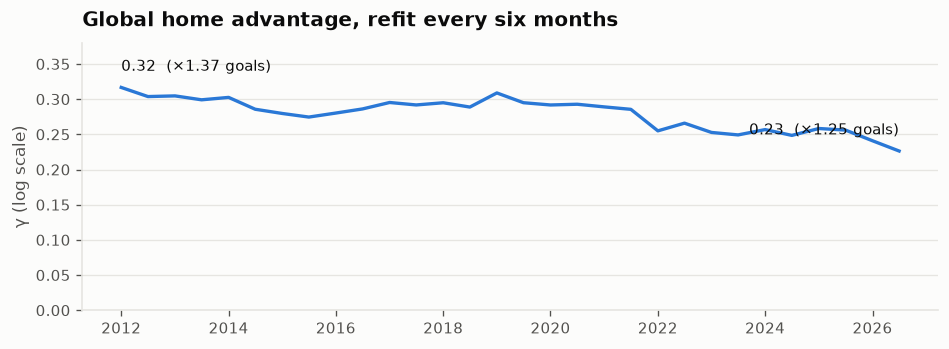

In [8]:
fig, ax = plt.subplots(figsize=(7.8, 2.8))
ax.plot(trace.date, trace.home_adv, color=viz.BLUE)
ax.set_title("Global home advantage, refit every six months")
ax.set_ylabel("γ (log scale)")
ax.set_ylim(0, trace.home_adv.max() * 1.2)
for i, ha in ((0, "left"), (len(trace) - 1, "right")):
    r = trace.iloc[i]
    ax.annotate(f"{r.home_adv:.2f}  (×{np.exp(r.home_adv):.2f} goals)",
                xy=(r.date, r.home_adv), xytext=(0, 10),
                textcoords="offset points", ha=ha, fontsize=9, color=viz.INK)
viz.despine(ax)
plt.show()

## 2. The divergence

2026 is simultaneously Jordan's **worst raw goal difference** and its **highest
strength estimate**. Both are correct.

**Plotted:** the same eleven years twice. **Top:** raw goal difference per match,
what a results table shows. **Bottom:** opponent-adjusted strength, what the
model shows. Two measures on different scales, so two panels sharing an x-axis —
never two y-axes on one plot.

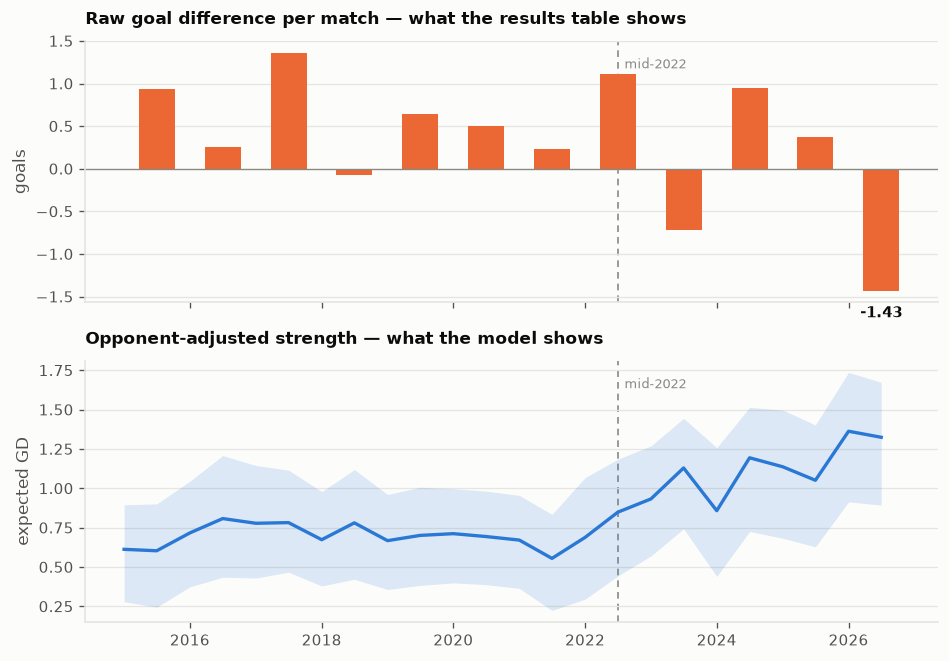

In [9]:
jor = team_view(df, "Jordan")
jor["year"] = jor.date.dt.year
raw = jor[jor.year.between(2015, 2026)].groupby("year").gd.mean().reset_index()
raw["date"] = pd.to_datetime(raw.year.astype(str) + "-07-01")

fig, axes = plt.subplots(2, 1, figsize=(7.8, 5.4), sharex=True)
ax = axes[0]
ax.bar(raw.date, raw.gd, width=200, color=viz.ORANGE, zorder=2)
ax.axhline(0, color=viz.INK_MUTED, linewidth=0.8)
viz.mark_split(ax)
ax.set_title("Raw goal difference per match — what the results table shows",
             fontsize=10)
ax.set_ylabel("goals")
worst = raw.loc[raw.gd.idxmin()]
ax.annotate(f"{worst.gd:+.2f}", xy=(worst.date, worst.gd), xytext=(0, -16),
            textcoords="offset points", ha="center", fontsize=9,
            color=viz.INK, fontweight="bold")
viz.despine(ax)

ax = axes[1]
s = strength[strength.date >= START]
ax.fill_between(s.date, s.strength_lo, s.strength_hi, color=viz.BLUE,
                alpha=0.15, linewidth=0)
ax.plot(s.date, s.strength, color=viz.BLUE)
viz.mark_split(ax)
ax.set_title("Opponent-adjusted strength — what the model shows", fontsize=10)
ax.set_ylabel("expected GD")
viz.despine(ax)
plt.show()

| year | raw GD/match | model strength |
|------|--------------|----------------|
| 2015 | +0.94 | 0.61 |
| 2023 | −0.71 | 0.93 |
| 2025 | +0.37 | 1.14 |
| 2026 | **−1.43** | **1.36** |

**This divergence is the project's headline**, and it is the argument for
building the squad layer at all: if the raw table is misleading about *whether*
Jordan improved, it is worth asking what changed underneath.

## 3. Is the rise Jordan's, or the region's?

A rise only means something against a baseline. If every comparable AFC side
improved over the same years, there is nothing specific to explain.

**This costs no extra data.** The strength model reads scores, and the spine
already holds every Iraq, Syria and UAE match. It costs almost no extra compute
either: every fit already estimates all 337 teams, so carrying three more through
the bootstrap is bookkeeping. More importantly, all four teams come from the
**same resample** on each draw, so the differences between them are paired and
get real intervals — not two separate intervals eyeballed against each other.

**Plotted:** the same strength trace for Jordan and three regional peers. Only
Jordan's interval is drawn, to keep the panel readable; the peers' are of similar
width. Each line is directly labelled as well as coloured, so identity never
rests on colour alone.

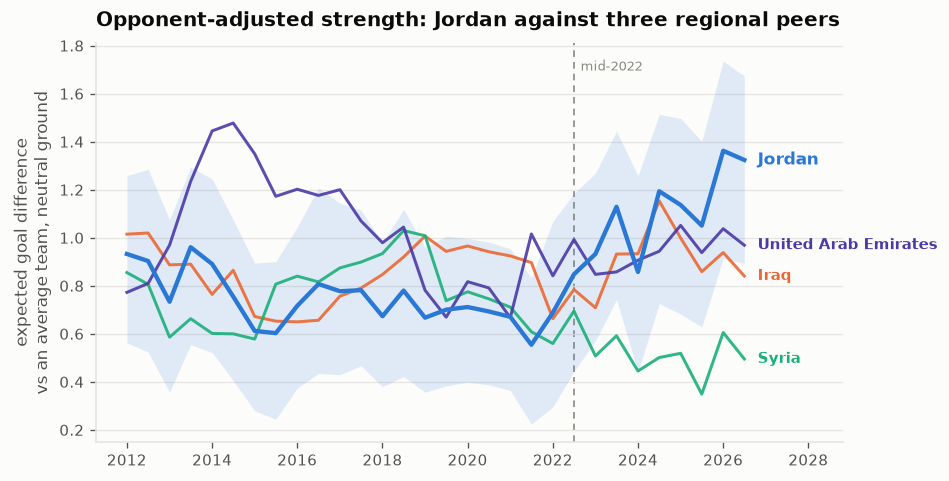

In [10]:
multi = pd.read_csv(OUT / "strength_ci_multi.csv", parse_dates=["date"])
PEERS = ["Iraq", "Syria", "United Arab Emirates"]

fig, ax = plt.subplots(figsize=(7.8, 3.9))
j = multi[multi.team == "Jordan"]
ax.fill_between(j.date, j.strength_lo, j.strength_hi, color=viz.BLUE,
                alpha=0.13, linewidth=0)
for name in PEERS:
    d = multi[multi.team == name]
    colour = viz.TEAM_COLOURS[name]
    ax.plot(d.date, d.strength, color=colour, linewidth=1.8, alpha=0.9)
    last = d.iloc[-1]
    ax.annotate(name, xy=(last.date, last.strength), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9,
                color=colour, fontweight="bold")
ax.plot(j.date, j.strength, color=viz.BLUE, linewidth=2.6, zorder=3)
last = j.iloc[-1]
ax.annotate("Jordan", xy=(last.date, last.strength), xytext=(8, 0),
            textcoords="offset points", va="center", fontsize=10,
            color=viz.BLUE, fontweight="bold")
viz.mark_split(ax)
ax.set_xlim(right=multi.date.max() + pd.Timedelta(days=850))
ax.set_title("Opponent-adjusted strength: Jordan against three regional peers")
ax.set_ylabel("expected goal difference" + chr(10) + "vs an average team, neutral ground")
viz.despine(ax)
plt.show()

The point is the shape: Jordan climbs, the other three do not. Note where UAE
starts — in 2015 it is the strongest of the four by a distance, and it declines
from there.

**Plotted:** Jordan minus each peer, computed **inside each bootstrap draw** so
the difference gets its own interval. The upper group compares the *rise* over
the window; the lower compares the *level* reached in 2026. A faded bar is an
interval that includes zero.

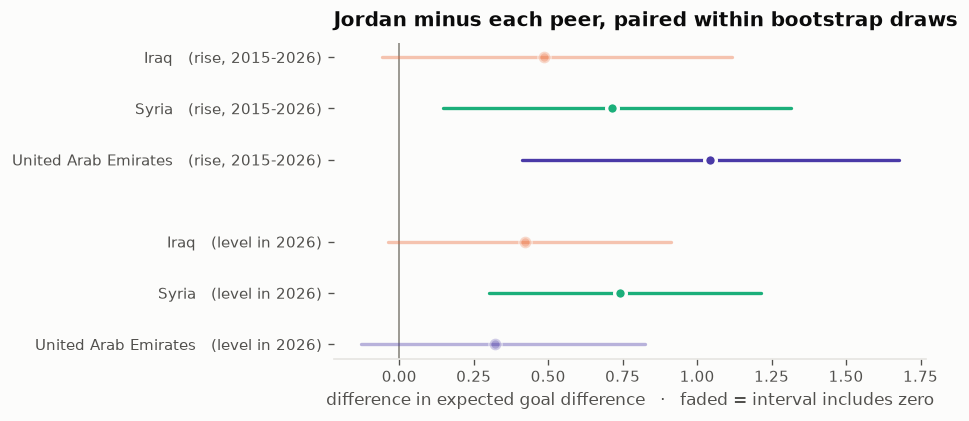

In [11]:
cmp = pd.read_csv(OUT / "placebo_strength_comparison.csv")
fig, ax = plt.subplots(figsize=(7.8, 3.4))
d = cmp[cmp.kind.isin(["rise vs peer", "2026 level vs peer"])].copy()
d["label"] = d.subject.str.replace("Jordan - ", "", regex=False)
# reversed: matplotlib stacks upward, and the rise is the primary claim
groups = [("2026 level vs peer", "level in 2026"), ("rise vs peer", "rise, 2015-2026")]
ypos, ticks, labels = 0, [], []
for kind, title in groups:
    sub = d[d.kind == kind].iloc[::-1]
    for _, r in sub.iterrows():
        solid = bool(r.excludes_zero)
        colour = viz.TEAM_COLOURS[r.label]
        ax.plot([r.lo, r.hi], [ypos, ypos], color=colour, linewidth=2,
                alpha=1.0 if solid else 0.38, solid_capstyle="round", zorder=2)
        ax.plot([r.estimate], [ypos], "o", color=colour, markersize=7, zorder=3,
                alpha=1.0 if solid else 0.45,
                markeredgecolor=viz.SURFACE, markeredgewidth=2)
        ticks.append(ypos)
        labels.append(f"{r.label}   ({title})")
        ypos += 1
    ypos += 0.6
ax.axvline(0, color=viz.INK_MUTED, linewidth=1.0, zorder=1)
ax.set_yticks(ticks)
ax.set_yticklabels(labels, fontsize=9)
ax.set_title("Jordan minus each peer, paired within bootstrap draws")
ax.set_xlabel("difference in expected goal difference   ·   "
              "faded = interval includes zero")
viz.despine(ax, keep=("bottom",))
ax.grid(axis="y", visible=False)
plt.show()

The two claims come apart, and that matters for how this gets written up.

**Supported — Jordan improved more than the region.** Against Syria (+0.714, CI
[+0.146, +1.314]) and UAE (+1.043, CI [+0.413, +1.679]) the difference in *rise*
is clean. Against Iraq it is +0.486, CI [−0.058, +1.116] — P(Jordan larger) =
0.94, but the interval touches zero, so **Iraq is the peer this design cannot
separate Jordan from**.

**Not supported — Jordan is now the strongest in the region.** On 2026 *level*
rather than change, Jordan is clearly above only Syria. UAE began at 1.350 and
fell to 1.038; Jordan rose to roughly where UAE already was a decade earlier.

So the defensible sentence is about **trajectory, not standing**. That also
sharpens what comes next: the thing to explain is a climb, not a peak.

## 4. Does the model predict Jordan's own matches?

The rise above is estimated from the **whole 49,000-match record** — every
opponent's other results feed Jordan's rating. So it is fair to ask two things
of it:

1. **Does it hold up match by match?** If the model is calibrated, Jordan's
   actual results should track its predictions with a slope near one.
2. **Could Jordan's own 143 matches have told us the same thing?**

The second question matters more than it looks, because it is the reason this
notebook exists rather than simply averaging Jordan's results.

**Plotted:** one dot per Jordan match since 2015 — what the model expected of it
before kickoff (x) against what happened (y) — with a fitted line per era. The
dashed diagonal is a perfectly calibrated model. The annotation gives the change
in slope and intercept with block-bootstrap intervals.

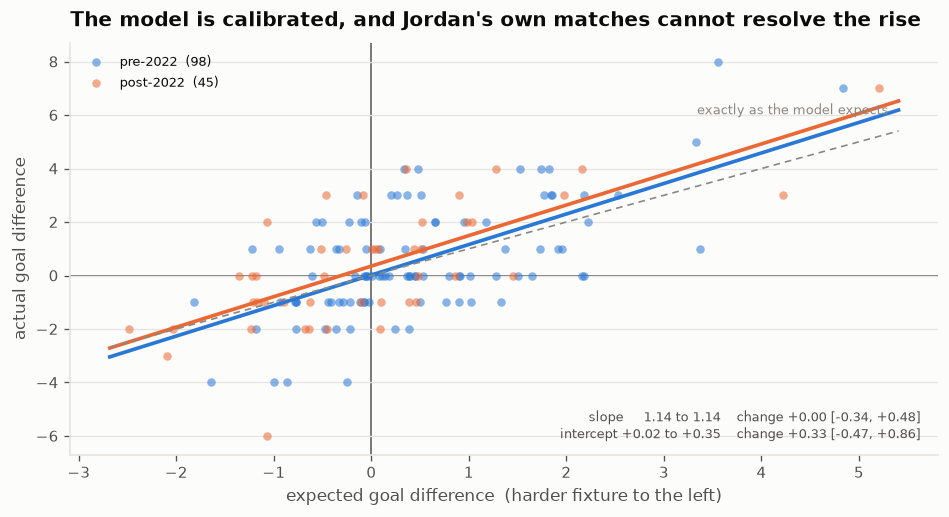

In [12]:
mt = pd.read_csv(SQUAD / "match_table.csv", parse_dates=["date"])
mt = mt[mt.date >= START].copy()
mt["era"] = np.where(mt.date < CUT, "pre", "post")
mt["blk"] = mt.date.dt.year * 2 + (mt.date.dt.month > 6)
BLK = {e: [d for _, d in mt[mt.era == e].groupby("blk")] for e in ("pre", "post")}

fits = {e: np.polyfit(d.expected_gd, d.gd, 1) for e, d in mt.groupby("era")}
draws = []
for _ in range(3000):
    p = {}
    for e in ("pre", "post"):
        s = pd.concat([BLK[e][i] for i in rng.integers(0, len(BLK[e]), len(BLK[e]))])
        if s.expected_gd.nunique() > 2:
            p[e] = np.polyfit(s.expected_gd, s.gd, 1)
    if len(p) == 2:
        draws.append([p["post"][0] - p["pre"][0], p["post"][1] - p["pre"][1]])
draws = np.array(draws)
d_slope = (fits["post"][0] - fits["pre"][0], *np.percentile(draws[:, 0], [2.5, 97.5]))
d_int = (fits["post"][1] - fits["pre"][1], *np.percentile(draws[:, 1], [2.5, 97.5]))

fig, ax = plt.subplots(figsize=(7.8, 4.2))
xs = np.linspace(mt.expected_gd.min() - 0.2, mt.expected_gd.max() + 0.2, 50)
for e, col in (("pre", viz.BLUE), ("post", viz.ORANGE)):
    d = mt[mt.era == e]
    ax.scatter(d.expected_gd, d.gd, s=26, color=col, alpha=0.55, linewidths=0,
               label=f"{e}-2022  ({len(d)})")
    ax.plot(xs, np.polyval(fits[e], xs), color=col, lw=2.2)
ax.plot(xs, xs, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)))
ax.annotate("exactly as the model expects", xy=(xs[-1], xs[-1]), xytext=(-6, 10),
            ha="right", textcoords="offset points", fontsize=8,
            color=viz.INK_MUTED)
ax.axhline(0, color=viz.INK_2, lw=0.9, zorder=0)
ax.axvline(0, color=viz.INK_2, lw=0.9, zorder=0)
ax.set_xlabel("expected goal difference  (harder fixture to the left)")
ax.set_ylabel("actual goal difference")
ax.set_title("The model is calibrated, and Jordan's own matches cannot "
             "resolve the rise")
ax.legend(fontsize=8, loc="upper left")
ax.annotate(f"slope     {fits['pre'][0]:.2f} to {fits['post'][0]:.2f}"
            f"    change {d_slope[0]:+.2f} [{d_slope[1]:+.2f}, {d_slope[2]:+.2f}]"
            + chr(10)
            + f"intercept {fits['pre'][1]:+.2f} to {fits['post'][1]:+.2f}"
            f"    change {d_int[0]:+.2f} [{d_int[1]:+.2f}, {d_int[2]:+.2f}]",
            xy=(0.98, 0.04), xycoords="axes fraction", ha="right", fontsize=8,
            color=viz.INK_2)
viz.despine(ax)
plt.show()

**The model is calibrated.** Jordan's results track its predictions with a slope
of **1.14** in both eras — close to the one-for-one a well-behaved model should
give — and the correlation is 0.62 before 2022 and 0.71 after. The residual
spread is about **1.65 goals**, which is football: the model accounts for
something like 40–50% of the variance in a single match's goal difference, and
nothing will account for much more.

🚨 **And Jordan's own matches cannot resolve the rise.** Fitted at match level
the improvement shows as the intercept moving **+0.02 to +0.35** — a change of
**+0.33, 95% [−0.43, +0.86]**, which spans zero. The slope change is **+0.00
[−0.34, +0.48]**, so there is no evidence the gain depends on the opponent
either, but the interval is far too wide to call that uniformity established.

**This is the whole argument for the model.** 143 matches, clustered into roughly
23 independent six-month blocks, carry very little. The estimate of **+0.717
[+0.203, +1.220]** is possible only because the fit pools the entire
international record — every result by every opponent sharpens Jordan's rating.
Averaging Jordan's own matches would have found nothing.

**One number worth carrying to notebook 05:** the post-2022 line crosses zero at
expected goal difference **−0.31**. Jordan now breaks even, on goal difference,
against opposition up to about a third of a goal stronger than itself. Past that
it loses — averaging **−0.79** against a side a goal better and **−1.36** against
one 1.5 better. *That is the margin any further improvement has to come out of.*

## 5. Where the cut comes from

Everything after this notebook splits Jordan's record at **2022-07-01**. The date
is not arbitrary and it is not this project's to choose — it is where the model
above puts the turn. But a date deserves a check, in a project that has already
disqualified one claim for growing monotonically with the split.

Two checks were run. The first is shown here: put the model's trace and the
squad's own history on one clock, and see whether they turn in the same place.

In [13]:
# What the squad was doing, on the same timeline. Two measures only:
# how settled the XI was, and how much new blood came in.
mt_all = (pd.read_csv(SQUAD / "match_table.csv", parse_dates=["date"])
          .sort_values("date"))
xi = mt_all.dropna(subset=["starting_xi"]).copy()
xi["ids"] = xi.starting_xi.map(lambda s: [p["id"] for p in json.loads(s) if p.get("id")])

# First-time starters need the FULL table, not the 2015+ window -- a player who
# debuted in 2013 is not a debutant in 2015.
seen, deb = set(), []
for r in xi.itertuples():
    deb.append({"date": r.date, "new": len([i for i in r.ids if i not in seen])})
    seen.update(r.ids)
deb = pd.DataFrame(deb)
deb = deb[deb.date >= START]

# Appearance rate: the share of the previous 24 months' matches that the average
# starter had already started. 0 if the XI is all new, 1 if the same eleven
# started every match for two years. Dividing by the matches AVAILABLE in the
# window makes it a rate -- raw counts accumulate with time and FBref's coverage
# starts in 2011, so an unadjusted version rises for reasons unrelated to Jordan.
caps_rate = {}
for r in xi.itertuples():
    prior = xi[(xi.date >= r.date - pd.Timedelta(days=730)) & (xi.date < r.date)]
    if len(prior) < 15:                # too little history to form a rate
        continue
    cc = {}
    for q in prior.itertuples():
        for i in q.ids:
            cc[i] = cc.get(i, 0) + 1
    caps_rate[r.match_id] = np.mean([cc.get(i, 0) for i in r.ids]) / len(prior)

mt["year"] = mt.date.dt.year
yr = []
for y, d in mt.groupby("year"):
    v = [caps_rate[m] for m in d.match_id if m in caps_rate]
    yr.append({"year": y, "n": len(d), "n_rate": len(v),
               "appearance rate": np.mean(v) if v else np.nan})
yr = pd.DataFrame(yr)
yr["debuts"] = deb.groupby(deb.date.dt.year).new.sum().reindex(yr.year).values
# The rate needs 24 months of prior lineups, so the first year of the window has
# almost none. The series starts once most of a year's matches can carry one.
RATE_FROM = int(yr.year[yr.n_rate / yr.n >= 0.5].min())
yrr = yr[yr.year >= RATE_FROM]

**Plotted, three panels on one clock.** **Top:** the model's strength trace, with
its worst point marked. **Middle:** how settled the XI was — the share of the
previous 24 months' matches the average starter had already started, marker area
being the matches behind each year. **Bottom:** first-time starters per year. The
shaded band is 2021; the dashed line is the cut.

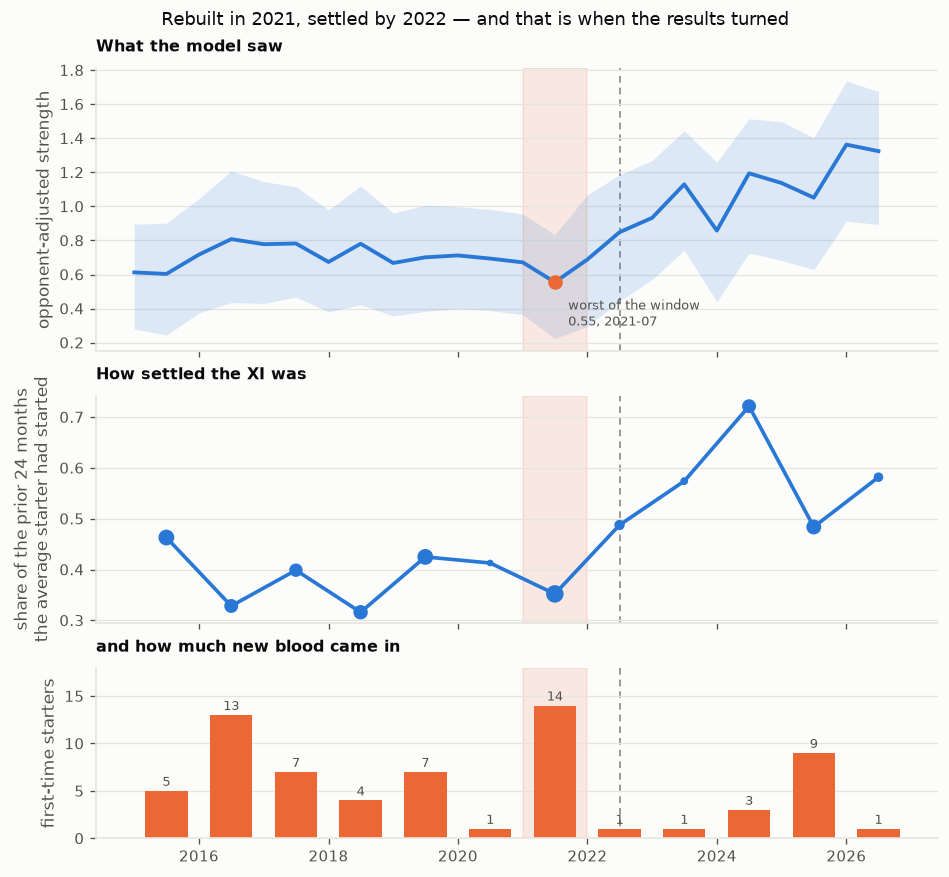

In [14]:
tr = pd.read_csv(OUT / "jordan_strength_ci.csv", parse_dates=["date"])
tr = tr[tr.date >= START]
fig, axes = plt.subplots(3, 1, figsize=(7.8, 7.2), sharex=True,
                         gridspec_kw={"height_ratios": [1.5, 1.2, 0.9]})
REBUILD = (pd.Timestamp("2021-01-01"), pd.Timestamp("2022-01-01"))
for ax in axes:
    ax.axvspan(*REBUILD, color=viz.ORANGE, alpha=0.13, zorder=0)
    ax.axvline(CUT, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)), zorder=0)

a = axes[0]
a.fill_between(tr.date, tr.strength_lo, tr.strength_hi, color=viz.BLUE,
               alpha=0.15, lw=0)
a.plot(tr.date, tr.strength, color=viz.BLUE, lw=2.3)
trough = tr.loc[tr.strength.idxmin()]
a.scatter([trough.date], [trough.strength], color=viz.ORANGE, s=60, zorder=4)
a.annotate(f"worst of the window" + chr(10)
           + f"{trough.strength:.2f}, {str(trough.date.date())[:7]}",
           xy=(trough.date, trough.strength), xytext=(8, -26),
           textcoords="offset points", fontsize=8, color=viz.INK_2)
a.set_ylabel("opponent-adjusted strength")
a.set_title("What the model saw", fontsize=9.5)
viz.despine(a)

b = axes[1]
mid = pd.to_datetime(yr.year.astype(str) + "-07-01")
midr = pd.to_datetime(yrr.year.astype(str) + "-07-01")
b.plot(midr, yrr["appearance rate"], color=viz.BLUE, lw=2.2)
b.scatter(midr, yrr["appearance rate"], color=viz.BLUE, s=yrr.n_rate * 4.5,
          zorder=3)
b.set_ylabel("share of the prior 24 months" + chr(10) + "the average starter had started")
b.set_title("How settled the XI was", fontsize=9.5)
viz.despine(b)

c = axes[2]
c.bar(mid, yr.debuts, width=240, color=viz.ORANGE)
for x_, v in zip(mid, yr.debuts):
    if v:
        c.annotate(int(v), (x_, v), xytext=(0, 3), ha="center",
                   textcoords="offset points", fontsize=8, color=viz.INK_2)
c.set_ylabel("first-time starters")
c.set_ylim(0, yr.debuts.max() * 1.28)
c.set_title("and how much new blood came in", fontsize=9.5)
viz.despine(c)
c.grid(axis="x", visible=False)

fig.suptitle("Rebuilt in 2021, settled by 2022 — and that is when the results turned",
             fontsize=11)
plt.show()

**An arc, not a step.** Jordan rebuilt through 2021 — **14 first-time starters in
21 matches** — and it cost them: the model's **lowest strength of the entire
window, 0.555 in July 2021**, below anything in 2015–19. Then the squad closed:
**two** first-time starters in the next two and a half years, the XI settling as
the same eleven accumulated time together, and strength climbing from 0.69 to a
peak above 1.1.

The cut sits just after the turn in both series. It is not a wall between two
regimes — it is the point where a squad assembled in 2021 started playing
together.

🚨 **The link is not tight, and the timeline should not be read as though it
were.** 2026H1 is the **highest strength in the window** with the XI already
loosening again, and 2025 reopened the squad — nine first-time starters — without
the results collapsing. Composition and strength move together over this **one
cycle**. That is a coincidence with uncertainty, which is all this design can
carry.

### The second check: slide the cut and watch the shape

A **change** ramps and then plateaus as the cut passes it; a **trend being
sliced** keeps climbing wherever you cut. Moving the split every six months from
2018 to 2024 and recomputing every squad measure:

`ramp` = travel from the earliest cut to 2022-07; `flat` = residual movement once
the cut is past the break.

| measure | ramp | flat | flat/ramp | |
|---|---|---|---|---|
| minutes top-11 | +0.275 | 0.007 | 0.02 | plateau |
| familiarity | +0.120 | 0.013 | 0.11 | plateau |
| appearance rate | +0.115 | 0.007 | 0.06 | plateau |
| top-3 goal share | +0.247 | 0.035 | 0.14 | plateau |
| **midfielder share of goals** | **−0.011** | 0.023 | — | **no break to find** |

Four of five plateau. The fifth **locates no date at all** — as large at a 2018
cut as at 2022 — and that guard fired before the data check that eventually
explained it (notebook 01, section 5: it was a labelling drift, and the finding
built on it is retired).

🚨 **The defensible claim is "no later than early 2022", not July 2022.** The
plateau is already reached at the 2022-01 cut, and at ~15 matches a year those
two cuts are a handful of fixtures apart. Nothing downstream depends on the finer
distinction. Note also that 2020-01 and 2020-07 give identical rows, as do
2022-07 and 2023-01 — no match falls between them, the shutdown and the post-2022
gap respectively.

## Summary

**Plotted, three panels.** **Top:** the climb, with its interval and the change
across the window. **Bottom left:** the attacking and defensive contributions to
that change, each with a bootstrap interval — a faded bar includes zero.
**Bottom right:** Jordan's rise minus each peer's.

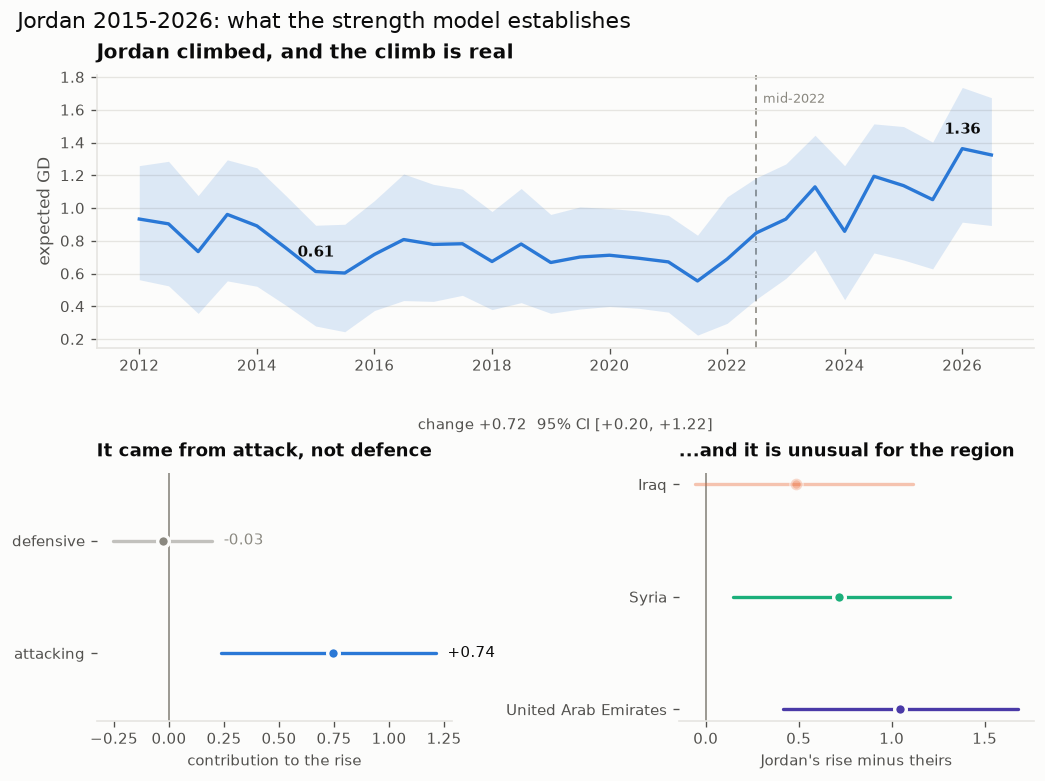

In [15]:
z = np.load(OUT / "bootstrap_draws.npz", allow_pickle=True)
bd = z["draws"]
tnames = [str(t) for t in z["teams"]]
pnames = [str(p) for p in z["params"]]
bdates = pd.to_datetime(z["dates"], unit="D")
S, A, D = pnames.index("strength"), pnames.index("attack"), pnames.index("defence")
jj = tnames.index("Jordan")
i0 = list(bdates).index(pd.Timestamp("2015-01-01"))
i1 = list(bdates).index(pd.Timestamp("2026-01-01"))
rise = bd[:, i1, S, jj] - bd[:, i0, S, jj]
atk_part = np.exp(bd[:, i1, A, jj]) - np.exp(bd[:, i0, A, jj])
def_part = np.exp(-bd[:, i0, D, jj]) - np.exp(-bd[:, i1, D, jj])


def band(x):
    lo, hi = np.nanpercentile(x, [2.5, 97.5])
    return float(np.nanmean(x)), float(lo), float(hi)


cmp_tbl = pd.read_csv(OUT / "placebo_strength_comparison.csv")
peers = cmp_tbl[cmp_tbl.kind == "rise vs peer"].copy()
peers["label"] = peers.subject.str.replace("Jordan - ", "", regex=False)

fig = plt.figure(figsize=(8.6, 6.4))
gs = fig.add_gridspec(2, 2, height_ratios=[1.1, 1])

ax = fig.add_subplot(gs[0, :])
ax.fill_between(strength.date, strength.strength_lo, strength.strength_hi,
                color=viz.BLUE, alpha=0.15, linewidth=0)
ax.plot(strength.date, strength.strength, color=viz.BLUE)
viz.mark_split(ax)
ax.set_title("Jordan climbed, and the climb is real")
ax.set_ylabel("expected GD")
for when in ("2015-01-01", "2026-01-01"):
    r = strength.loc[strength.date == when].iloc[0]
    ax.annotate(f"{r.strength:.2f}", xy=(r.date, r.strength), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=9,
                color=viz.INK, fontweight="bold")
mu, lo, hi = band(rise)
ax.annotate(f"change {mu:+.2f}  95% CI [{lo:+.2f}, {hi:+.2f}]",
            xy=(0.5, -0.30), xycoords="axes fraction", ha="center",
            fontsize=9, color=viz.INK_2)
viz.despine(ax)

ax = fig.add_subplot(gs[1, 0])
for i, (name, arr) in enumerate([("attacking", atk_part), ("defensive", def_part)]):
    mu, lo, hi = band(arr)
    solid = lo * hi > 0
    colour = viz.BLUE if solid else viz.INK_MUTED
    ax.plot([lo, hi], [i, i], color=colour, linewidth=2, zorder=2,
            alpha=1.0 if solid else 0.5, solid_capstyle="round")
    ax.plot([mu], [i], "o", color=colour, markersize=7, zorder=3,
            markeredgecolor=viz.SURFACE, markeredgewidth=2)
    ax.annotate(f"{mu:+.2f}", xy=(hi, i), xytext=(7, 0),
                textcoords="offset points", va="center", fontsize=9,
                color=viz.INK if solid else viz.INK_MUTED)
ax.axvline(0, color=viz.INK_MUTED, linewidth=1.0, zorder=1)
ax.set_yticks([0, 1])
ax.set_yticklabels(["attacking", "defensive"])
ax.set_ylim(-0.6, 1.6)
ax.set_title("It came from attack, not defence", fontsize=11)
ax.set_xlabel("contribution to the rise", fontsize=9)
viz.despine(ax, keep=("bottom",))
ax.grid(axis="y", visible=False)

ax = fig.add_subplot(gs[1, 1])
peers = peers.iloc[::-1].reset_index(drop=True)
for i, r in peers.iterrows():
    solid = bool(r.excludes_zero)
    colour = viz.TEAM_COLOURS[r.label]
    ax.plot([r.lo, r.hi], [i, i], color=colour, linewidth=2, zorder=2,
            alpha=1.0 if solid else 0.38, solid_capstyle="round")
    ax.plot([r.estimate], [i], "o", color=colour, markersize=7, zorder=3,
            alpha=1.0 if solid else 0.45,
            markeredgecolor=viz.SURFACE, markeredgewidth=2)
ax.axvline(0, color=viz.INK_MUTED, linewidth=1.0, zorder=1)
ax.set_yticks(range(len(peers)))
ax.set_yticklabels(peers.label, fontsize=9)
ax.set_title("...and it is unusual for the region", fontsize=11)
ax.set_xlabel("Jordan's rise minus theirs", fontsize=9)
viz.despine(ax, keep=("bottom",))
ax.grid(axis="y", visible=False)

fig.suptitle("Jordan 2015-2026: what the strength model establishes",
             fontsize=13, x=0.01, ha="left", color=viz.INK)
plt.show()

### What this notebook establishes

**Jordan improved, and the improvement is real.** +0.717 in expected goal
difference between 2015 and 2026, 95% CI [+0.203, +1.220]. The interval clears
zero, so this is not an artefact of a thin record.

**The improvement is attacking, not defensive.** Attacking contribution +0.744
[+0.238, +1.212]; defensive −0.027 [−0.255, +0.196], indistinguishable from zero.
Their difference, +0.771 [+0.229, +1.282], is the test that matters and it clears
zero. Jordan scores more relative to its opponents than it used to; it does not
concede measurably less.

**The improvement is unusual for the region.** Of Jordan, Iraq, Syria and UAE,
only Jordan's rise is distinguishable from zero.

**The turn is locatable, no later than early 2022**, and it arrives immediately
after a squad rebuild rather than on top of one.

### What it does not establish

| | |
|---|---|
| ❌ 2026 is Jordan's peak | highest point estimate, not separable from 2023 or 2025 |
| ❌ Jordan is now the region's strongest | only clearly above Syria on 2026 *level* |
| ❌ Jordan improved more than Iraq | +0.486 [−0.058, +1.116] — touches zero |
| ❌ any causal claim | squad, coaching and scheduling all move together across this date |

### The one-sentence version

> Between 2015 and 2026 Jordan climbed by about 0.7 goals of expected goal
> difference — a rise its regional peers did not match — and essentially all of
> that came from scoring more rather than conceding less.

---

**Next:** the rise is attacking, so the question is where the extra goals came
from. Notebook 03 starts with the two things that decide it — **who was picked,
and who they played.**